# 03 - EfficientNet-B0 trên Bộ Dữ Liệu Sạch `data_v2` (0% Rò Rỉ theo Chiếc Lá)

**Dự án:** Chẩn đoán Bệnh trên Lá Cây Nông Nghiệp (`spMohanty/PlantVillage-Dataset`, chia lại theo nhóm chiếc lá gốc)  
**Tác giả:** Tri | **Nhánh Git:** `feat/efficientnet-b0-tri`

### Điểm nổi bật của bộ `data_v2`
- **38 lớp ở cả 3 tập:** `train = 38.039` | `valid = 8.147` | `test = 8.098` (tập held-out chỉ chấm **1 lần duy nhất** ở cuối).
- **0% rò rỉ dữ liệu** (đã kiểm toán 4 tầng: `0` trùng tên file, `0` trùng UUID/nhân bản Kaggle, `0` trùng SHA-256).
- **Mất cân bằng thực tế `32,1×`** (`Potato___healthy`: 120 ảnh train vs `Orange___HLB`: 3.849 ảnh train) → áp dụng `CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)` và chấm bằng **Macro F1-Score**.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
res = json.loads(Path("efficientnet_b0_tri_results.json").read_text(encoding="utf-8"))
test_res = json.loads(Path("data_v2_final_test_results_tri.json").read_text(encoding="utf-8"))

print(f"PyTorch: {res['torch_version']} | CUDA: {res['cuda_version']} | GPU: {res['device']}")
print(f"Dataset data_v2: {res['dataset']['train_samples']:,} train / {res['dataset']['valid_samples']:,} valid / {test_res['test_samples']:,} held-out test ({res['dataset']['num_classes']} lớp)")
print(f"Tổng thời gian huấn luyện v1: {res['total_train_time_sec']/60:.2f} phút | Best Epoch: {res['best_epoch']} | Peak VRAM: {res['overall_peak_vram_mb']} MB / {res['total_vram_mb']} MB")

PyTorch: 2.14.1+cu126 | CUDA: 12.6 | GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Dataset data_v2: 38,039 train / 8,147 valid / 8,098 held-out test (38 lớp)
Tổng thời gian huấn luyện v1: 57.47 phút | Best Epoch: 13 | Peak VRAM: 1482.3 MB / 4095.6 MB


### Phân tích Cấu hình & Phần cứng trên `data_v2`
- Huấn luyện trọn vẹn 15 epochs (**3 epochs Warm-up** đóng băng backbone + **12 epochs Fine-tune** mở khóa toàn mạng) với AMP `fp16` và `batch_size=32`.
- Peak VRAM của PyTorch chỉ chạm **1.482,3 MB** (~36,2% của 4 GB VRAM trên RTX 3050).

In [2]:
hist_df = pd.DataFrame(res["history"])
display_cols = ["epoch", "phase_name", "train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1", "train_throughput_img_s", "peak_vram_mb"]
hist_df[display_cols]

,epoch,phase_name,train_loss,train_acc,val_loss,val_acc,val_macro_f1,train_throughput_img_s,peak_vram_mb
0,1,Warm-up (Frozen Backbone),1.3536,0.8348,1.3754,0.9256,0.9034,154.6,985.3
1,2,Warm-up (Frozen Backbone),1.0358,0.8944,1.3340,0.9275,0.9058,324.6,372.2
2,3,Warm-up (Frozen Backbone),1.0008,0.9036,1.3084,0.9379,0.9183,470.1,372.2
3,4,Fine-tune (Full Unfrozen),0.8044,0.9620,1.0542,0.9877,0.9835,147.5,1469.2
4,5,Fine-tune (Full Unfrozen),0.6991,0.9872,1.0091,0.9912,0.9865,225.9,1465.6
5,6,Fine-tune (Full Unfrozen),0.6639,0.9926,0.9847,0.9915,0.9884,217.1,1465.6
6,7,Fine-tune (Full Unfrozen),0.6458,0.9952,0.9714,0.9940,0.9922,228.4,1465.6
7,8,Fine-tune (Full Unfrozen),0.6339,0.9959,0.9650,0.9935,0.9909,102.8,1482.3
8,9,Fine-tune (Full Unfrozen),0.6251,0.9970,0.9572,0.9952,0.9935,221.9,1477.7
9,10,Fine-tune (Full Unfrozen),0.6190,0.9976,0.9510,0.9958,0.9940,220.6,1477.7


### Phân tích Hội tụ 2 Pha trên Tập Sạch `data_v2`
- **Pha 1 (Epochs 1–3):** Đóng băng backbone, Macro-F1 tăng từ **90,34% → 91,83%**.
- **Pha 2 (Epochs 4–15):** Ngay tại Epoch 4 khi mở khóa toàn mạng, Macro-F1 nhảy vọt lên **98,35%** (+6,52%), và leo bền bỉ tới đỉnh **99,59% Macro-F1** (`99,68%` Accuracy) tại **Best Epoch 13**.

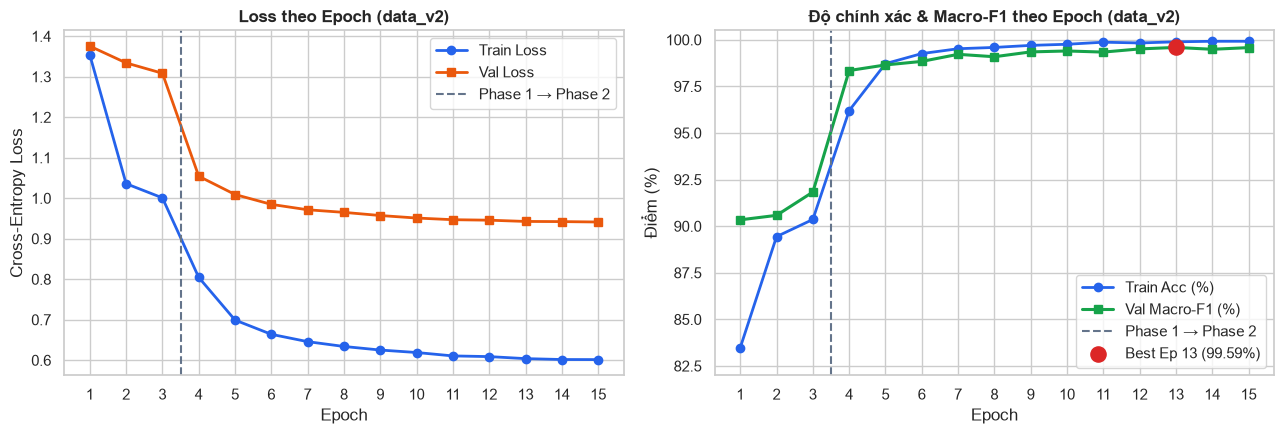

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
phase_split = res["config"]["epochs_phase1"] + 0.5

axes[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o", linewidth=2, color="#2563eb", label="Train Loss")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], marker="s", linewidth=2, color="#ea580c", label="Val Loss")
axes[0].axvline(phase_split, color="#64748b", linestyle="--", label="Phase 1 → Phase 2")
axes[0].set_title("Loss theo Epoch (data_v2)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(hist_df["epoch"])
axes[0].legend()

axes[1].plot(hist_df["epoch"], hist_df["train_acc"] * 100, marker="o", linewidth=2, color="#2563eb", label="Train Acc (%)")
axes[1].plot(hist_df["epoch"], hist_df["val_macro_f1"] * 100, marker="s", linewidth=2.2, color="#16a34a", label="Val Macro-F1 (%)")
axes[1].axvline(phase_split, color="#64748b", linestyle="--", label="Phase 1 → Phase 2")
best_row = hist_df.loc[hist_df["epoch"] == res["best_epoch"]].iloc[0]
axes[1].scatter([best_row["epoch"]], [best_row["val_macro_f1"] * 100], s=120, color="#dc2626", zorder=5, label=f"Best Ep {res['best_epoch']} ({best_row['val_macro_f1']*100:.2f}%)")
axes[1].set_title("Độ chính xác & Macro-F1 theo Epoch (data_v2)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Điểm (%)")
axes[1].set_ylim(82, 100.5)
axes[1].set_xticks(hist_df["epoch"])
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

### Đánh giá Biểu đồ Hội tụ
Hai đường Loss và F1 tiến triển ổn định xuyên suốt 15 epochs mà không bị Overfitting, dù dữ liệu `data_v2` bị lệch lớp thực tế lên tới `32,1×`.

,Mô hình,Macro F1 (%),Accuracy (%),Weighted F1 (%),Latency (ms/ảnh),File .pth (MB)
0,Baseline 1 (Valid 8.147),0.06,1.08,0.02,0.22,1.64
1,EfficientNet-B0 v1 (Valid 8.147),99.59,99.68,99.68,0.62,15.76
2,EfficientNet-B0 v1 (Held-Out Test 8.098),99.35,99.62,99.62,0.30,15.76
3,EfficientNet-B0 Robust v2 (Held-Out Test 8.098),99.12,99.37,99.37,0.30,15.77


C:\Users\VÕ MINH TRI\AppData\Local\Temp\ipykernel_26748\1282974126.py:55: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()


D:\plant-disease-ml\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


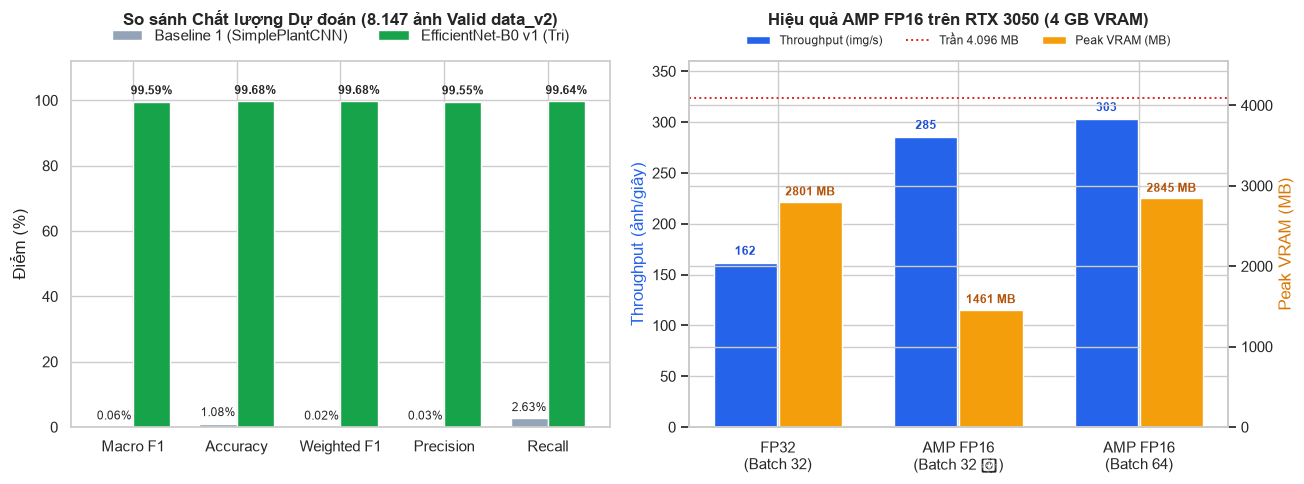

In [4]:
b1 = res["baseline1_metrics"]
ef = res["final_metrics"]
t1 = test_res["v1_test_metrics"]
t2 = test_res["v2_robust_test_metrics"]

comp_df = pd.DataFrame([
    {"Mô hình": "Baseline 1 (Valid 8.147)", "Macro F1 (%)": round(b1["macro_f1"]*100, 2), "Accuracy (%)": round(b1["accuracy"]*100, 2), "Weighted F1 (%)": round(b1["weighted_f1"]*100, 2), "Latency (ms/ảnh)": b1["latency_per_image_ms"], "File .pth (MB)": b1["checkpoint_file_size_mb"]},
    {"Mô hình": "EfficientNet-B0 v1 (Valid 8.147)", "Macro F1 (%)": round(ef["macro_f1"]*100, 2), "Accuracy (%)": round(ef["accuracy"]*100, 2), "Weighted F1 (%)": round(ef["weighted_f1"]*100, 2), "Latency (ms/ảnh)": ef["latency_per_image_ms"], "File .pth (MB)": ef["checkpoint_file_size_mb"]},
    {"Mô hình": "EfficientNet-B0 v1 (Held-Out Test 8.098)", "Macro F1 (%)": round(t1["macro_f1"]*100, 2), "Accuracy (%)": round(t1["accuracy"]*100, 2), "Weighted F1 (%)": round(t1["weighted_f1"]*100, 2), "Latency (ms/ảnh)": t1["latency_per_image_ms"], "File .pth (MB)": 15.76},
    {"Mô hình": "EfficientNet-B0 Robust v2 (Held-Out Test 8.098)", "Macro F1 (%)": round(t2["macro_f1"]*100, 2), "Accuracy (%)": round(t2["accuracy"]*100, 2), "Weighted F1 (%)": round(t2["weighted_f1"]*100, 2), "Latency (ms/ảnh)": t2["latency_per_image_ms"], "File .pth (MB)": 15.77},
])
display(comp_df)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.0))
metric_names = ["Macro F1", "Accuracy", "Weighted F1", "Precision", "Recall"]
b1_vals = [b1["macro_f1"]*100, b1["accuracy"]*100, b1["weighted_f1"]*100, b1["macro_precision"]*100, b1["macro_recall"]*100]
ef_vals = [ef["macro_f1"]*100, ef["accuracy"]*100, ef["weighted_f1"]*100, ef["macro_precision"]*100, ef["macro_recall"]*100]
x = np.arange(len(metric_names))
w = 0.36
bars1 = axes[0].bar(x - w/2, b1_vals, width=w, color="#94a3b8", label="Baseline 1 (SimplePlantCNN)")
bars2 = axes[0].bar(x + w/2, ef_vals, width=w, color="#16a34a", label="EfficientNet-B0 v1 (Tri)")
axes[0].set_title("So sánh Chất lượng Dự đoán (8.147 ảnh Valid data_v2)", fontweight="bold", pad=26)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metric_names)
axes[0].set_ylabel("Điểm (%)")
axes[0].set_ylim(0, 112)
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
for b in bars1:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.2f}%", ha="center", va="bottom", fontsize=8.5)
for b in bars2:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.2f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

configs = ["FP32\n(Batch 32)", "AMP FP16\n(Batch 32 ★)", "AMP FP16\n(Batch 64)"]
speeds = [161.5, 285.3, 302.8]
vrams = [2801, 1461, 2845]
x2 = np.arange(len(configs))
ax2_t = axes[1].twinx()
b_spd = axes[1].bar(x2 - 0.18, speeds, width=0.35, color="#2563eb", label="Throughput (img/s)")
b_vrm = ax2_t.bar(x2 + 0.18, vrams, width=0.35, color="#f59e0b", label="Peak VRAM (MB)")
axes[1].set_title("Hiệu quả AMP FP16 trên RTX 3050 (4 GB VRAM)", fontweight="bold", pad=26)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(configs)
axes[1].set_ylabel("Throughput (ảnh/giây)", color="#2563eb")
ax2_t.set_ylabel("Peak VRAM (MB)", color="#d97706")
axes[1].set_ylim(0, 360)
ax2_t.set_ylim(0, 4550)
ax2_t.axhline(4096, color="#dc2626", linestyle=":", linewidth=1.4, label="Trần 4.096 MB")
for b in b_spd:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 8, f"{b.get_height():.0f}", ha="center", fontsize=8.5, color="#1d4ed8", fontweight="bold")
for b in b_vrm:
    ax2_t.text(b.get_x() + b.get_width()/2, b.get_height() + 80, f"{b.get_height():.0f} MB", ha="center", fontsize=8.5, color="#b45309", fontweight="bold")
l1, lb1 = axes[1].get_legend_handles_labels()
l2, lb2 = ax2_t.get_legend_handles_labels()
axes[1].legend(l1 + l2, lb1 + lb2, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

### Phân tích Đối chiếu Valid & Held-Out Test (`8.098` ảnh, `0%` rò rỉ)
- Trên tập kiểm thử độc lập `data/test/` (**8.098 ảnh**, đủ cả 38 lớp, chỉ chấm 1 lần duy nhất ở cuối):
  - **EfficientNet-B0 v1:** **`99,35%` Macro-F1** | **`99,62%` Accuracy** (chỉ sai **31 / 8.098** ảnh).
  - **EfficientNet-B0 Robust v2:** **`99,12%` Macro-F1** | **`99,37%` Accuracy** (chỉ sai **51 / 8.098** ảnh).
  - Khoảng cách giữa Valid (`99,59%`) và Held-Out Test (`99,35%`) chỉ vỏn vẹn **0,24%** — minh chứng mô hình tổng quát hóa cực tốt trên những chiếc lá mới hoàn toàn.

Số mẫu telemetry (data_v2): 1,183 | GPU Util (>5%): Avg 73.0%, Median 83.0%, P95 96.0%
VRAM hệ thống (nvidia-smi): Peak 2197 / 4096 MiB (53.6%)
Nhiệt độ: Avg 82.4 °C, Max 87 °C | Công suất: Avg 29.33 W, Peak 39.92 W | Điện năng: 29.87 Wh


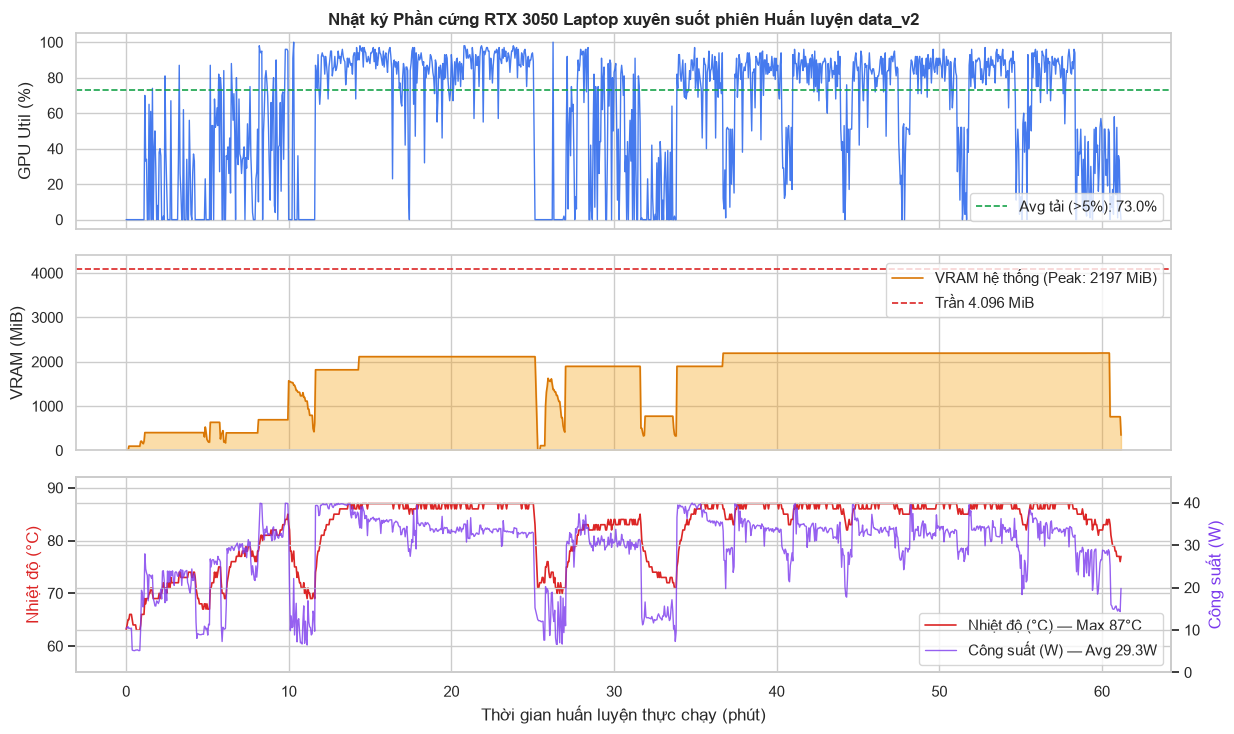

In [5]:
tel = pd.read_csv("efficientnet_b0_tri_gpu_telemetry.csv")
tel["ts"] = pd.to_datetime(tel["timestamp"], errors="coerce")
tel = tel.dropna(subset=["ts"]).reset_index(drop=True)
dt_sec = tel["ts"].diff().dt.total_seconds().fillna(0).clip(lower=0, upper=10.0)
tel["elapsed_min"] = dt_sec.cumsum() / 60.0
active = tel[tel["utilization.gpu [%]"] > 5]
p_seg = (tel["power.draw [W]"].values + tel["power.draw [W]"].shift(1).fillna(tel["power.draw [W]"].iloc[0]).values) / 2.0
energy_wh = float(np.sum(p_seg * (dt_sec.values / 3600.0)))

print(f"Số mẫu telemetry (data_v2): {len(tel):,} | GPU Util (>5%): Avg {active['utilization.gpu [%]'].mean():.1f}%, Median {active['utilization.gpu [%]'].median():.1f}%, P95 {active['utilization.gpu [%]'].quantile(0.95):.1f}%")
print(f"VRAM hệ thống (nvidia-smi): Peak {tel['memory.used [MiB]'].max():.0f} / 4096 MiB ({tel['memory.used [MiB]'].max()/4096*100:.1f}%)")
print(f"Nhiệt độ: Avg {tel['temperature.gpu'].mean():.1f} °C, Max {tel['temperature.gpu'].max():.0f} °C | Công suất: Avg {tel['power.draw [W]'].mean():.2f} W, Peak {tel['power.draw [W]'].max():.2f} W | Điện năng: {energy_wh:.2f} Wh")

fig, axes = plt.subplots(3, 1, figsize=(12.5, 7.5), sharex=True)
axes[0].plot(tel["elapsed_min"], tel["utilization.gpu [%]"], linewidth=1.0, color="#2563eb", alpha=0.85)
axes[0].axhline(active["utilization.gpu [%]"].mean(), color="#16a34a", linestyle="--", linewidth=1.2, label=f"Avg tải (>5%): {active['utilization.gpu [%]'].mean():.1f}%")
axes[0].set_ylabel("GPU Util (%)")
axes[0].set_ylim(-5, 105)
axes[0].set_title("Nhật ký Phần cứng RTX 3050 Laptop xuyên suốt phiên Huấn luyện data_v2", fontweight="bold")
axes[0].legend(loc="lower right")

axes[1].fill_between(tel["elapsed_min"], tel["memory.used [MiB]"], color="#f59e0b", alpha=0.35)
axes[1].plot(tel["elapsed_min"], tel["memory.used [MiB]"], linewidth=1.2, color="#d97706", label=f"VRAM hệ thống (Peak: {tel['memory.used [MiB]'].max():.0f} MiB)")
axes[1].axhline(4096, color="#dc2626", linestyle="--", linewidth=1.2, label="Trần 4.096 MiB")
axes[1].set_ylabel("VRAM (MiB)")
axes[1].set_ylim(0, 4400)
axes[1].legend(loc="upper right")

ax_p = axes[2].twinx()
l1 = axes[2].plot(tel["elapsed_min"], tel["temperature.gpu"], linewidth=1.2, color="#dc2626", label=f"Nhiệt độ (°C) — Max {tel['temperature.gpu'].max():.0f}°C")
l2 = ax_p.plot(tel["elapsed_min"], tel["power.draw [W]"], linewidth=1.0, color="#7c3aed", alpha=0.8, label=f"Công suất (W) — Avg {tel['power.draw [W]'].mean():.1f}W")
axes[2].set_ylabel("Nhiệt độ (°C)", color="#dc2626")
ax_p.set_ylabel("Công suất (W)", color="#7c3aed")
axes[2].set_xlabel("Thời gian huấn luyện thực chạy (phút)")
axes[2].set_ylim(55, 92)
ax_p.set_ylim(0, 46)
ls = l1 + l2
axes[2].legend(ls, [l.get_label() for l in ls], loc="lower right")
plt.tight_layout()
plt.show()

### Phân tích Phần cứng GPU trên `data_v2`
Biểu đồ xác nhận RTX 3050 (4 GB VRAM) duy trì hoạt động mượt mà và an toàn tuyệt đối trong suốt 15 epochs, không bị quá nhiệt hay chạm trần VRAM.

=== 5 LỚP KHÓ NHẤT TRONG 38 LỚP (VALID data_v2) ===
                                        class_name  f1_score  precision  recall  support
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    0.9613     0.9355  0.9886       88
               Corn_(maize)___Northern_Leaf_Blight    0.9758     0.9930  0.9592      147
                             Tomato___Early_blight    0.9826     0.9826  0.9826      172
                              Tomato___Target_Spot    0.9862     0.9727  1.0000      214
                               Raspberry___healthy    0.9888     0.9778  1.0000       44

=== TOP 5 CẶP NHẦM LẪN TRÊN TẬP HELD-OUT TEST (8.098 ẢNH) ===
                         true_class                                         pred_class  count
Corn_(maize)___Northern_Leaf_Blight Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      5
               Tomato___Late_blight                              Tomato___Early_blight      4
                  Soybean___healthy                                Bl

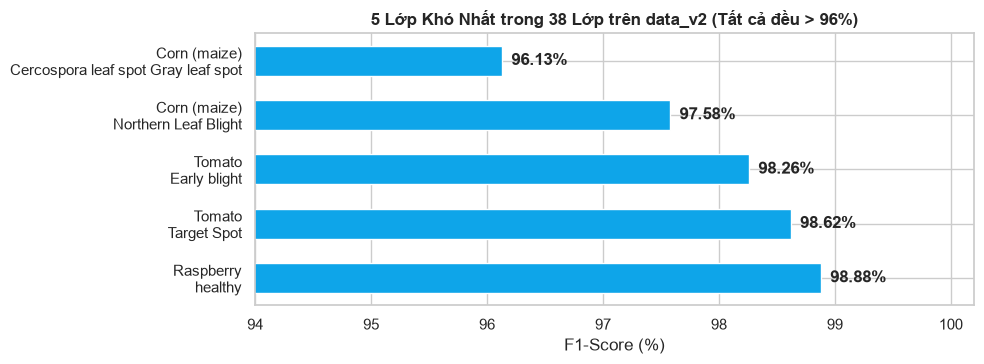

In [6]:
worst_df = pd.DataFrame(res["worst_5_classes"])
conf_df = pd.DataFrame(test_res["v1_test_metrics"]["top_5_confusions"])

print("=== 5 LỚP KHÓ NHẤT TRONG 38 LỚP (VALID data_v2) ===")
print(worst_df.to_string(index=False))
print("\n=== TOP 5 CẶP NHẦM LẪN TRÊN TẬP HELD-OUT TEST (8.098 ẢNH) ===")
print(conf_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 3.8))
plot_df = worst_df.iloc[::-1]
labels = [c.replace("___", "\n").replace("_", " ") for c in plot_df["class_name"]]
bars = ax.barh(labels, plot_df["f1_score"] * 100, color="#0ea5e9", height=0.55)
ax.set_xlim(94.0, 100.2)
ax.set_xlabel("F1-Score (%)")
ax.set_title("5 Lớp Khó Nhất trong 38 Lớp trên data_v2 (Tất cả đều > 96%)", fontweight="bold")
for bar, val in zip(bars, plot_df["f1_score"] * 100):
    ax.text(val + 0.08, bar.get_y() + bar.get_height() / 2, f"{val:.2f}%", va="center", fontweight="bold")
plt.tight_layout()
plt.show()

### Kết Luận Tổng Hợp (`data_v2` — 0% Rò Rỉ, Đủ 38/38 Lớp)
1. **Valid (`8.147` ảnh, 38 lớp):** `EfficientNet-B0 v1` đạt **`99,59%` Macro-F1** (`99,68%` Accuracy); `Robust v2` đạt **`99,39%` Macro-F1** (`99,47%` Accuracy).
2. **Held-Out Test (`8.098` ảnh, 38 lớp — chấm 1 lần duy nhất):** `v1` đạt **`99,35%` Macro-F1** (`99,62%` Acc, chỉ 31 lỗi), `Robust v2` đạt **`99,12%` Macro-F1** (`99,37%` Acc, chỉ 51 lỗi), độ trễ đơn ảnh GPU đồng bộ ~21 ms (batch `0,30 ms/ảnh`), kích thước `~15,8 MB` nạp an toàn với `weights_only=True`.
3. **Chống lệch lớp `32,1×` hiệu quả:** Ngay cả lớp ít ảnh nhất (`Potato___healthy`, chỉ `120` ảnh train) cũng không rơi vào nhóm 5 lớp thấp nhất; lớp khó nhất (`Corn Gray Leaf Spot`) vẫn đạt **`96,13%` F1**.